# Regressor screening (training years only)

A first look at the 40 regressors defined in `docs/features.md`, before any model uses them:

1. **Coverage:** how often each regressor is available, by year.
2. **Distributions:** what each regressor looks like.
3. **What the baseline misses:** how strongly each regressor relates to the reference baseline's errors, by lead time, overall and in quiet no-CME wind. That's where the baseline fails most (`final_baseline_analysis.ipynb`).
4. **Redundancy:** which regressors carry the same information.
5. **Findings.**

**Data:**
- **Training years only.** Nothing from the eval year (2025-10-20 → 2026-10-20) is loaded, so this screening can't leak eval information into feature or model choices.
- **Baseline errors:** the reference baseline is refitted for each of the two tuning folds (`training.final_baseline.FOLDS`) on all hours before the fold, then run walk-forward over the fold, 2023-10-20 → 2025-10-20. These are out-of-sample errors, 2,908 runs.
- **Residual** = actual − forecast, so a positive residual means the baseline forecast too low.
- **Association:** Spearman rank correlation. It is robust to the skewed regressors, and it is not a causal or predictive score: a model has to show the gain.

The table comes from `python -m training.pull_features all`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import TwoSlopeNorm

from feature_engineering import registry
from feature_engineering.recurrence import last_observed, targets
from models.final_baseline import FinalBaseline, cycle_positions
from training import solar_wind_events as ev
from training.datasets import DATA_START, TRAIN_END, load_train
from training.final_baseline import FOLDS, load_config
from training.pull_features import load_table

plt.rcParams.update(
    {"figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3, "axes.titlesize": 9,
     "axes.labelsize": 8, "xtick.labelsize": 7, "ytick.labelsize": 7}
)
pd.set_option("display.precision", 3)
pd.set_option("display.width", 160)

GROUP_COLORS = {
    "plasma": "#2a78d6", "field": "#eb6834", "cme": "#e87ba4", "coronal hole": "#1baf7a",
    "eruptive": "#eda100", "surface": "#6250d6",
}
BLOCKS = {"1-24 h": slice(0, 24), "25-48 h": slice(24, 48), "49-72 h": slice(48, 72)}
QUIET = ["slow wind", "intermediate"]


def fmt(table):
    return table.map(lambda x: f"{x:.3g}" if isinstance(x, float) else x)


table = load_table()
table = table[(table.index >= DATA_START) & (table.index < TRAIN_END)]
assert table.index.max() < TRAIN_END
print(f"{len(table)} forecast times, {table.index.min():%Y-%m-%d} .. {table.index.max():%Y-%m-%d}; "
      f"{table.shape[1]} regressors")

5844 forecast times, 2021-10-20 .. 2025-10-19; 40 regressors


## 1. Coverage

The share of forecast times with a real value for each group's regressors, by year. A gap is
filled with the training median plus a flag. Gaps are dominated by spacecraft data gaps (ACE
SWEPAM degrades in some periods), missing AIA images, and OMNI's F10.7 lag at the very end.

In [2]:
groups = {g: [f.name for f in registry.FEATURES if f.group == g] for g in registry.GROUPS}
by_year = pd.DataFrame({
    g: table[cols].notna().mean(axis=1).groupby(table.index.year).mean()
    for g, cols in groups.items()
})
by_year.index.name = "year"
by_year["forecast times"] = table.groupby(table.index.year).size()
per_feature = table.notna().mean().rename("available")
print("lowest coverage:", per_feature.nsmallest(5).round(3).to_dict())
fmt(by_year)

lowest coverage: {'log_p47_slope_6h': 0.888, 'density_slope_6h': 0.916, 'ch_cm_d0': 0.943, 'ch_east_d0': 0.943, 'ch_disk_d0': 0.943}


,plasma,field,cme,coronal hole,eruptive,surface,forecast times
year,,,,,,,
2021,0.912,0.907,0.836,1,1,1,292
2022,0.962,0.966,0.945,0.988,1,1,1460
2023,0.976,0.978,0.963,0.999,1,1,1460
2024,0.969,0.974,0.968,0.913,1,1,1464
2025,0.996,0.993,0.984,0.845,1,1,1168


## 2. Distributions

One panel per regressor over the training years, coloured by group. Counts are on a log scale
where the regressor is heavily skewed. These ranges are what the imputation medians
(`assets/feature_climatology.json`) come from.

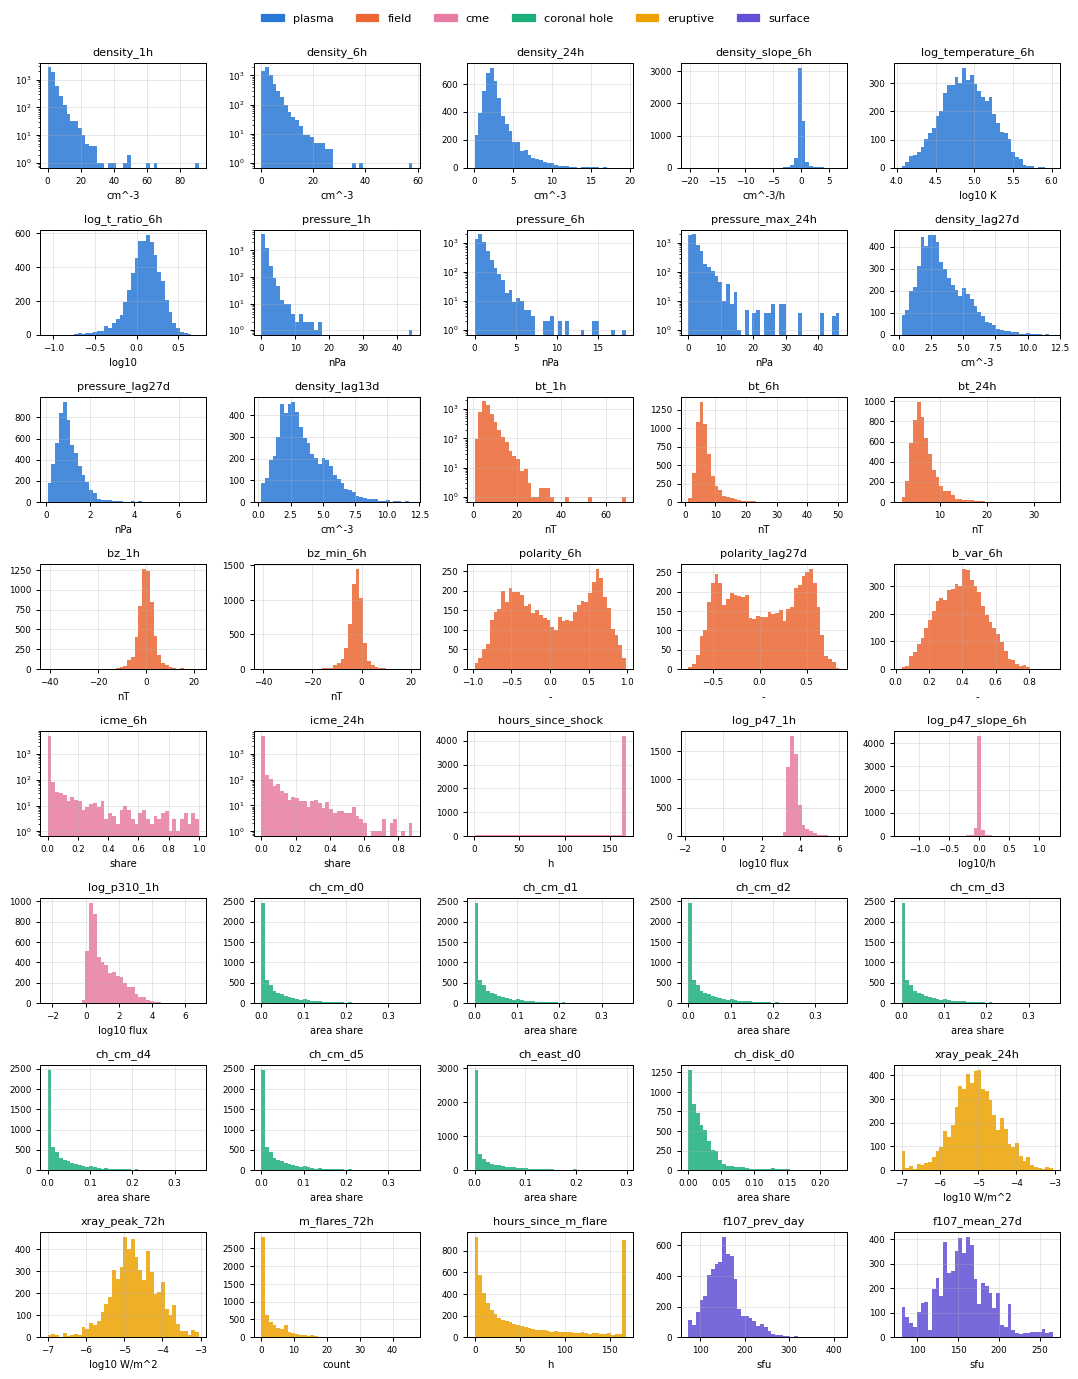

In [3]:
fig, axes = plt.subplots(8, 5, figsize=(12, 15))
for ax, f in zip(axes.flat, registry.FEATURES, strict=True):
    v = table[f.name].dropna()
    ax.hist(v, bins=40, color=GROUP_COLORS[f.group], alpha=0.85)
    if v.skew() > 3:
        ax.set_yscale("log")
    ax.set_title(f.name)
    ax.set_xlabel(f.unit)
for ax in axes.flat[len(registry.FEATURES):]:
    ax.axis("off")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in GROUP_COLORS.values()]
fig.legend(handles, GROUP_COLORS, loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=6,
           frameon=False, fontsize=9)
fig.tight_layout()

## 3. What the baseline misses

### 3.1 Out-of-sample baseline errors on the training years

For each tuning fold, the chosen configuration (`training/final_baseline_config.json`) is fitted
on all hours before the fold and run at every 6-hourly `t0` in it, as in tuning. Each run is then
labelled with a regime: CME, possible CME, stream arrival, fast stream, slow wind or intermediate.
The labels use the same in-situ rules as the analysis notebook (`training.solar_wind_events`).

In [4]:
series = load_train()
values = series.to_numpy(dtype=float)
config = load_config()
parts = []
for start, end in FOLDS:
    model = FinalBaseline(config).fit(series[series.index < start])
    pos = cycle_positions(series.index, start, end)
    parts.append((pos, model.forecast(values, pos)))
pos = np.concatenate([p for p, _ in parts])
forecast = np.concatenate([f for _, f in parts])
t0s = series.index[pos]
actual = targets(values, pos)
last = last_observed(values, pos)
residual = actual - forecast

minutes = ev.load_conditions(FOLDS[0][0] - pd.Timedelta(days=30), TRAIN_END)
hourly = minutes.resample("h").mean().reindex(series.index)
events = ev.detect_icmes(hourly, ev.detect_shocks(minutes))
cme = ev.cme_mask(hourly.index, events)
possible = ev.cme_mask(hourly.index, events, ("possible ICME",))
arrivals = ev.detect_stream_arrivals(hourly["speed"], cme | possible)
regime = pd.Series(ev.classify_runs(t0s, actual, cme, arrivals, possible), index=t0s)

runs = pd.DataFrame({b: np.nanmean(residual[:, s], axis=1) for b, s in BLOCKS.items()}, index=t0s)
runs["regime"] = regime
summary = runs.groupby("regime", observed=True).agg(["mean", "count"])
summary = summary.loc[:, [(b, "mean") for b in BLOCKS] + [("1-24 h", "count")]]
summary.columns = [f"mean residual {b}" for b in BLOCKS] + ["runs"]
print(f"{len(t0s)} runs, {t0s.min():%Y-%m-%d} .. {t0s.max():%Y-%m-%d}")
fmt(summary)

[solar_wind_events] plasma: 760/760 days


[solar_wind_events] mag: 760/760 days


C:\Users\ching\Documents\REPOS\benchlab-competition\src\training\solar_wind_events.py:249: RuntimeWarning: Mean of empty slice
  elif np.nanmean(a) >= 550:
C:\Users\ching\Documents\REPOS\benchlab-competition\src\training\solar_wind_events.py:251: RuntimeWarning: All-NaN slice encountered
  elif np.nanmax(a) < 450:


2908 runs, 2023-10-21 .. 2025-10-16


C:\Users\ching\AppData\Local\Temp\ipykernel_19156\4199307805.py:24: RuntimeWarning: Mean of empty slice
  runs = pd.DataFrame({b: np.nanmean(residual[:, s], axis=1) for b, s in BLOCKS.items()}, index=t0s)


,mean residual 1-24 h,mean residual 25-48 h,mean residual 49-72 h,runs
regime,,,,
CME,-17.5,-38.8,-47.1,613
possible CME,-32.3,-71.9,-99.3,77
stream arrival,-12.1,-10.2,5.44,444
fast stream,22.2,23.2,-31.6,117
slow wind,-45.4,-102,-125,740
intermediate,-33.9,-75.1,-110,902


### 3.2 Association with the baseline's errors

The table gives, for each regressor, the Spearman correlation between its value at `t0` and the
run's mean residual in each lead block (1–24 h, 25–48 h, 49–72 h).
- **All runs:** every run, rows ordered by the strongest absolute correlation at 25–48 h.
- **Quiet wind:** runs in slow or intermediate wind, where the baseline over-forecasts most.

A positive correlation means a high value goes with a baseline forecast that is too low.
Each correlation uses only the runs where the regressor is available. With about 2,900
runs, |ρ| above roughly 0.05 is beyond chance, but neighbouring runs overlap, so treat small
values with caution.

In [5]:
def spearman(x, y):
    ok = np.isfinite(x) & np.isfinite(y)
    if ok.sum() < 50:
        return np.nan
    return pd.Series(x[ok]).rank().corr(pd.Series(y[ok]).rank())


feats = table.reindex(t0s)
quiet = regime.isin(QUIET).to_numpy()
corr = {}
for name in registry.NAMES:
    x = feats[name].to_numpy(dtype=float)
    row = {}
    for b in BLOCKS:
        y = runs[b].to_numpy()
        row[("all runs", b)] = spearman(x, y)
        row[("quiet wind", b)] = spearman(x[quiet], y[quiet])
    corr[name] = row
corr = pd.DataFrame(corr).T
corr.columns = pd.MultiIndex.from_tuples(corr.columns)
corr.insert(0, "group", [registry.BY_NAME[n].group for n in corr.index])
order = corr[("all runs", "25-48 h")].abs().sort_values(ascending=False).index
corr = corr.loc[order]
print(f"quiet-wind runs: {quiet.sum()} of {len(quiet)}")
fmt(corr)

quiet-wind runs: 1656 of 2908


,group,all runs,quiet wind,all runs,quiet wind,all runs,quiet wind
,,1-24 h,1-24 h,25-48 h,25-48 h,49-72 h,49-72 h
bt_1h,field,0.374,0.364,0.347,0.375,0.241,0.243
bt_6h,field,0.346,0.343,0.33,0.36,0.223,0.229
bt_24h,field,0.264,0.273,0.262,0.286,0.165,0.158
ch_cm_d2,coronal hole,0.133,0.0284,0.226,0.131,0.189,0.17
ch_cm_d1,coronal hole,0.058,-0.0281,0.194,0.0405,0.256,0.121
density_6h,plasma,0.194,0.162,0.172,0.143,0.179,0.151
density_24h,plasma,0.184,0.171,0.164,0.169,0.167,0.172
pressure_6h,plasma,0.169,0.118,0.162,0.113,0.0842,0.0158
pressure_1h,plasma,0.151,0.0772,0.155,0.0912,0.0832,0.0198


C:\Users\ching\AppData\Local\Temp\ipykernel_19156\767023938.py:2: PerformanceWarning: dropping on a non-lexsorted multi-index without a level parameter may impact performance.
  m = corr.drop(columns="group").to_numpy(dtype=float)


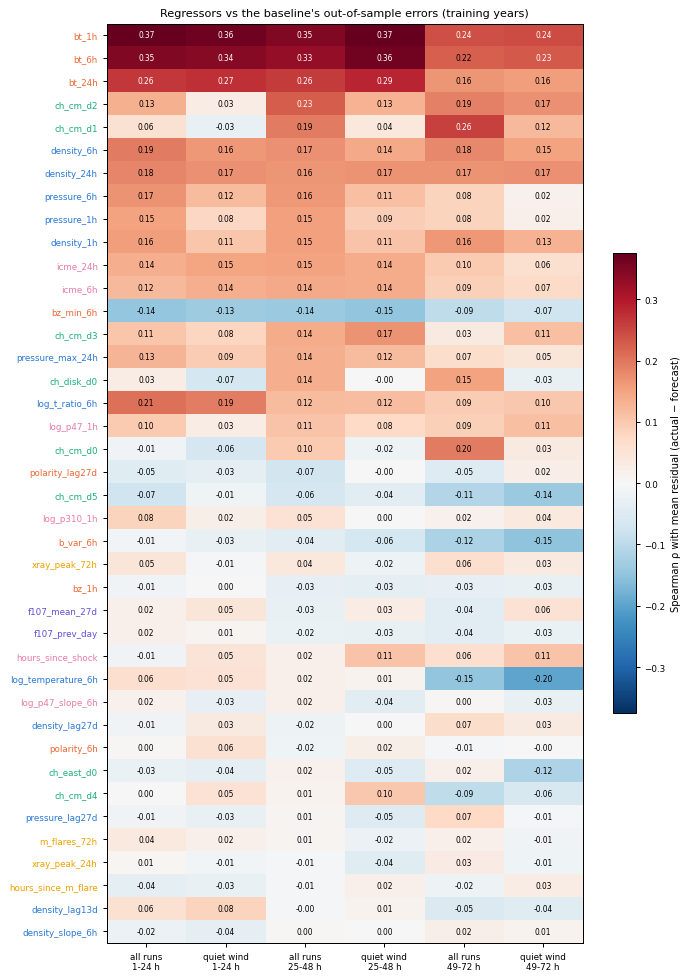

In [6]:
fig, ax = plt.subplots(figsize=(8, 11))
m = corr.drop(columns="group").to_numpy(dtype=float)
lim = np.nanmax(np.abs(m))
im = ax.imshow(m, cmap="RdBu_r", norm=TwoSlopeNorm(0, -lim, lim), aspect="auto")
ax.set_yticks(range(len(corr)), corr.index)
ax.set_xticks(range(m.shape[1]), [f"{a}\n{b}" for a, b in corr.columns[1:]])
ax.grid(False)
for tick, name in zip(ax.get_yticklabels(), corr.index, strict=True):
    tick.set_color(GROUP_COLORS[registry.BY_NAME[name].group])
for i in range(m.shape[0]):
    for j in range(m.shape[1]):
        if np.isfinite(m[i, j]):
            ax.text(j, i, f"{m[i, j]:.2f}", ha="center", va="center", fontsize=6,
                    color="white" if abs(m[i, j]) > 0.6 * lim else "black")
fig.colorbar(im, ax=ax, shrink=0.5, label="Spearman ρ with mean residual (actual − forecast)")
ax.set_title("Regressors vs the baseline's out-of-sample errors (training years)")
fig.tight_layout()

### 3.3 A closer look at the strongest regressors

For the eight regressors most associated with the 25–48 h errors, the baseline's mean residual is
shown in deciles of the regressor (equal-count bins), for all runs and for quiet-wind runs. A flat
line means the regressor adds nothing the speed history didn't already give; a slope is the error a
model using it could remove.

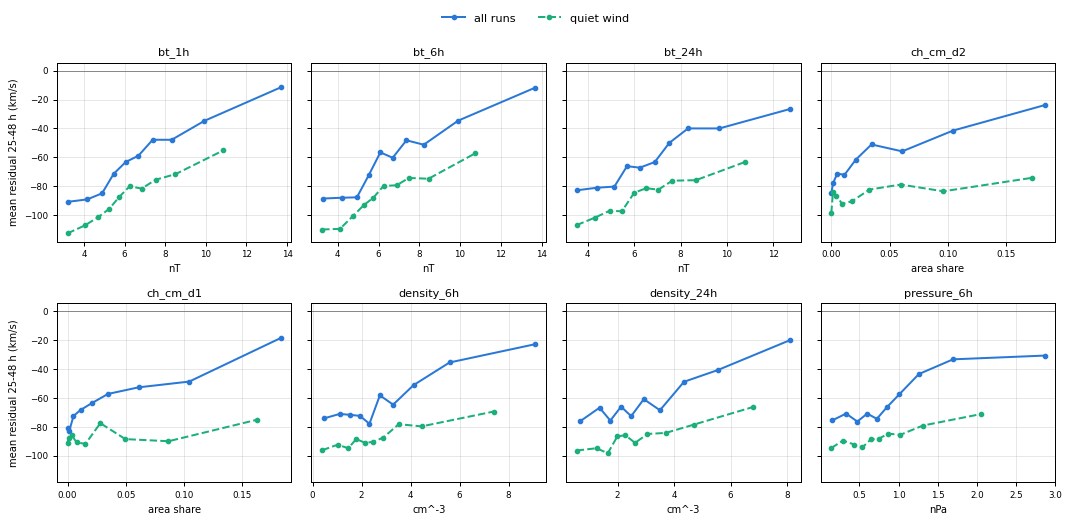

In [7]:
top = list(corr.index[:8])
fig, axes = plt.subplots(2, 4, figsize=(12, 5.5), sharey=True)
for ax, name in zip(axes.flat, top, strict=True):
    x = feats[name]
    for sel, label, style in [(np.ones(len(x), bool), "all runs", {"color": "#2a78d6"}),
                              (quiet, "quiet wind", {"color": "#1baf7a", "ls": "--"})]:
        d = pd.DataFrame({"x": x[sel], "y": runs["25-48 h"][sel]}).dropna()
        if d["x"].nunique() < 4:
            continue
        bins = pd.qcut(d["x"], 10, duplicates="drop")
        g = d.groupby(bins, observed=True).agg(x=("x", "median"), y=("y", "mean"))
        ax.plot(g["x"], g["y"], marker="o", ms=3.5, lw=1.6, label=label, **style)
    ax.axhline(0, color="#8a8984", lw=0.8)
    ax.set_title(name)
    ax.set_xlabel(registry.BY_NAME[name].unit)
for ax in axes[:, 0]:
    ax.set_ylabel("mean residual 25-48 h (km/s)")
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2, frameon=False,
           fontsize=9)
fig.tight_layout()

### 3.4 Coronal holes and lead time

A hole crossing the central meridian should matter most at the lead that matches its travel time
to Earth. For a slow 400 km/s transit that is about 4.3 days, and for a fast 700 km/s one about
2.5 days. The panel shows the correlation of each daily coronal-hole regressor (`ch_cm_d0` … `d5`)
with the residual at every lead, for all runs. If the physics holds, the band of strongest
correlation should move to later leads for more recent images (smaller d).

,lead of max ρ,max ρ
ch_cm_d0,66,0.206
ch_cm_d1,60,0.259
ch_cm_d2,48,0.229
ch_cm_d3,30,0.155
ch_cm_d4,26,0.0332
ch_cm_d5,26,-0.0381


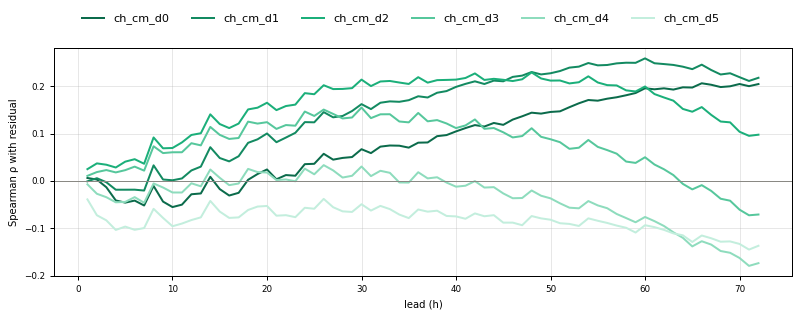

In [8]:
lead_corr = pd.DataFrame({
    f"ch_cm_d{d}": [spearman(feats[f"ch_cm_d{d}"].to_numpy(dtype=float), residual[:, k])
                    for k in range(72)]
    for d in range(6)
}, index=np.arange(1, 73))
fig, ax = plt.subplots(figsize=(9, 3.2))
shades = ["#0b6b4b", "#138a61", "#1baf7a", "#56c79c", "#8edcbd", "#c3eedd"]
for (name, col), color in zip(lead_corr.items(), shades, strict=True):
    ax.plot(col.index, col, color=color, lw=1.6, label=name)
ax.axhline(0, color="#8a8984", lw=0.8)
ax.set_xlabel("lead (h)")
ax.set_ylabel("Spearman ρ with residual")
fig.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=6, frameon=False, fontsize=9)
fig.tight_layout()
best = lead_corr.idxmax().to_frame("lead of max ρ").join(lead_corr.max().rename("max ρ"))
fmt(best)

## 4. Redundancy

The table lists pairs of regressors with |Spearman ρ| ≥ 0.8 between them, over all training
forecast times. A model may need only one of each pair.

In [9]:
rank = table[registry.NAMES].rank()
cc = rank.corr()
pairs = [(a, b, cc.loc[a, b]) for i, a in enumerate(registry.NAMES)
         for b in registry.NAMES[i + 1:] if abs(cc.loc[a, b]) >= 0.8]
fmt(pd.DataFrame(pairs, columns=["regressor", "with", "rho"]).sort_values("rho", key=abs,
                                                                          ascending=False))

,regressor,with,rho
5,bt_1h,bt_6h,0.932
0,density_1h,density_6h,0.883
8,xray_peak_72h,m_flares_72h,0.876
4,pressure_1h,pressure_6h,0.874
1,density_1h,pressure_1h,0.859
6,bt_6h,bt_24h,0.842
3,density_6h,pressure_6h,0.842
9,m_flares_72h,hours_since_m_flare,-0.835
7,xray_peak_24h,hours_since_m_flare,-0.835
2,density_6h,density_24h,0.802


## 5. Findings

All numbers are from the training years (validation folds 2023-10 → 2025-10, 2,908 runs) and
are associations, not model gains.

- **The baseline's errors are mostly a level problem in quiet wind.** In slow and intermediate wind
  the mean residual is −45 to −34 km/s at 1–24 h, growing to −125 to −110 km/s at 49–72 h (section 3.1).
  The baseline forecasts too high there, as it does in the eval year.
- **The field strength is the strongest single signal** (ρ ≈ 0.35 at 1–48 h, 0.24 at 49–72 h).
  - It holds just as well in quiet wind: with the weakest field (Bt ≈ 3 nT), the quiet-wind runs are over-forecast by about 110 km/s at 25–48 h; with Bt ≈ 10 nT, by about 55 km/s.
  - A weak, steady field marks wind that will stay slow, which the speed history alone doesn't capture.
- **Coronal holes add information at the leads physics predicts.**
  - Each daily strip area peaks at a different lead: 5–6 days before t0 adds nothing; 3 days before peaks at 30 h, 2 days at 48 h, 1 day at 60 h and the day of t0 at 66 h (ρ up to 0.26).
  - That is a 3–4-day travel time, as expected for wind from a hole at the central meridian, and the signal is strongest at 49–72 h, where the baseline is weakest.
  - In quiet wind it is weaker (ρ ≈ 0.1–0.17): a hole there signals the end of the quiet spell.
- **Density, pressure and the cold-plasma (CME) share follow** (ρ ≈ 0.10–0.20). High density and a compressed, cold or CME-like plasma go with the baseline forecasting too low.
- **Little or nothing at this level:**
  - flares, F10.7, the EPAM particle trend, the lagged 27-day density/pressure/polarity, the eastern strip, and sector polarity: |ρ| ≤ 0.07 on average;
  - the lagged in-situ regressors largely duplicate what the recurrence terms of the baseline already use;
  - flares matter for individual CME arrivals, which a rank correlation over all runs can't show.
  - These are kept for now: a model can still find value in combinations or rare events, but they are the first candidates to drop.
- **Redundancy:** Bt 1 h / 6 h / 24 h, density 1 h / 6 h / pressure, and the three flare measures are near-duplicates (|ρ| ≥ 0.8). One of each family may be enough.

**Caveats:**
- The "quiet wind" label depends on what happened during the run (the observed future speed), so splitting by it is a diagnostic, not a usable input.
- The coronal-hole regressors have archive gaps (December 2024, about 2025-09-12 → 2025-12-16, part of March 2026): about 6% of training forecast times are imputed, and the first two months of the eval year will be.
- Correlations ignore that the baseline is already partly right: the next step is to add the leading regressors (Bt, coronal-hole strip areas by lead, density, CME share) to the per-lead regression and test the gain on the training folds.